In [1]:
import pandas as pd
import numpy as np
from PIL import Image

df_train = pd.read_csv("../data/train.csv")

path = df_train["path"][0]
img = np.array(Image.open(path))

print("Class:", df_train["label"][0])
print("Shape:", img.shape)
print("Min:", img.min(), "Max:", img.max())
print("First pixel (R, G, B):", img[0, 0])

Class: sea
Shape: (150, 150, 3)
Min: 0 Max: 255
First pixel (R, G, B): [104 116 130]


In [2]:
img_norm = img / 255.0

print("Before:", img.min(), img.max(), img.dtype)
print("After:", img_norm.min(), img_norm.max(), img_norm.dtype)
print("First pixel:", img_norm[0, 0])

Before: 0 255 uint8
After: 0.0 1.0 float64
First pixel: [0.40784314 0.45490196 0.50980392]


In [3]:
import tensorflow as tf

IMG_SIZE = 150

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img

x = load_image(df_train["path"][0])
print("Shape:", x.shape)
print("Min:", float(tf.reduce_min(x)), "Max:", float(tf.reduce_max(x)))

I0000 00:00:1791904402.805912   40720 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791904402.806266   40720 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791904402.840569   40720 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791904403.578546   40720 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Shape: (150, 150, 3)
Min: 0.0 Max: 1.0


E0000 00:00:1791904404.352808   40720 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
df_val = pd.read_csv("../data/val.csv")
df_test = pd.read_csv("../data/test.csv")

class_names = sorted(df_train["label"].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}

for df in (df_train, df_val, df_test):
    df["label_id"] = df["label"].map(class_to_idx)

print(class_to_idx)
df_train.head()

{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


,path,label,label_id
0,../data/seg_train_test/seg_train/sea/12357.jpg,sea,4
1,../data/seg_train_test/seg_train/mountain/2428...,mountain,3
2,../data/seg_train_test/seg_train/glacier/3199.jpg,glacier,2
3,../data/seg_train_test/seg_train/glacier/22829...,glacier,2
4,../data/seg_train_test/seg_train/mountain/7865...,mountain,3


In [5]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_example(path, label):
    return load_image(path), label

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label_id"].values)
    )
    if training:
        ds = ds.shuffle(len(df), seed=42)
    ds = ds.map(load_example, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(df_train, training=True)
val_ds = make_dataset(df_val)
test_ds = make_dataset(df_test)

for images, labels in train_ds.take(1):
    print("Images batch:", images.shape)
    print("Labels batch:", labels.shape)
    print("Labels:", labels.numpy())

Images batch: (32, 150, 150, 3)
Labels batch: (32,)
Labels: [4 2 4 4 3 4 5 2 2 0 1 0 4 1 5 3 1 0 0 4 2 2 0 2 5 1 1 1 3 3 0 4]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0134368].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0204003].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0096095].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0132334].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.003039].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0088483].


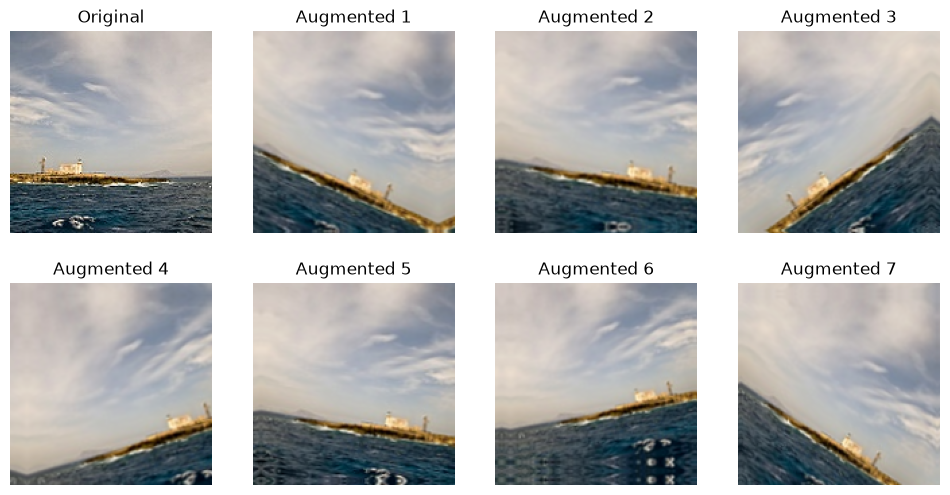

In [6]:
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
])

original = load_image(df_train["path"][0])
original_batch = tf.expand_dims(original, 0)

plt.figure(figsize=(12, 6))

plt.subplot(2, 4, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

for i in range(2, 9):
    augmented = data_augmentation(original_batch, training=True)
    plt.subplot(2, 4, i)
    plt.imshow(augmented[0])
    plt.title(f"Augmented {i-1}")
    plt.axis("off")

plt.show()

Images batch: (32, 150, 150, 3)
Min: 0.0 Max: 1.0


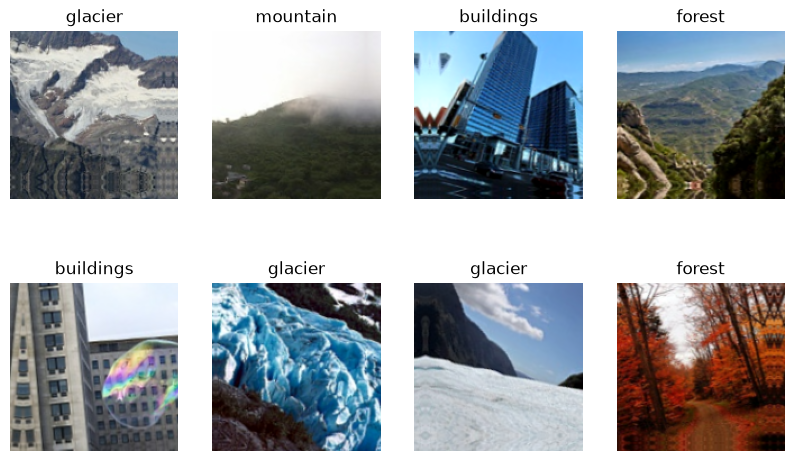

In [7]:
def augment(images, labels):
    images = data_augmentation(images, training=True)
    images = tf.clip_by_value(images, 0.0, 1.0)
    return images, labels

train_ds_aug = train_ds.map(augment, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Check one batch
for images, labels in train_ds_aug.take(1):
    print("Images batch:", images.shape)
    print("Min:", float(tf.reduce_min(images)), "Max:", float(tf.reduce_max(images)))

plt.figure(figsize=(10, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()

In [8]:
conv = layers.Conv2D(filters=32, kernel_size=3, activation="relu")

batch_one = images[:1]
out = conv(batch_one)

print("Input shape:", batch_one.shape)
print("Output shape:", out.shape)

Input shape: (1, 150, 150, 3)
Output shape: (1, 148, 148, 32)


In [9]:
pool = layers.MaxPooling2D(pool_size=2)

out_pooled = pool(out)

print("Before pooling:", out.shape)
print("After pooling:", out_pooled.shape)

Before pooling: (1, 148, 148, 32)
After pooling: (1, 74, 74, 32)


In [10]:
blocks = keras.Sequential([
    keras.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
])

blocks.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,248 (364.25 KB)

 Trainable params: 93,248 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
head = keras.Sequential([
    keras.Input(shape=(17, 17, 128)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(6, activation="softmax"),
])

head.summary()

fake = tf.random.normal((1, 17, 17, 128))
result = head(fake)
print("Output:", result.numpy().round(3))
print("Sum:", float(tf.reduce_sum(result)))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 774 (3.02 KB)

 Trainable params: 774 (3.02 KB)

 Non-trainable params: 0 (0.00 B)

Output: [[0.179 0.153 0.166 0.162 0.169 0.17 ]]
Sum: 1.0


In [12]:
model = keras.Sequential([
    keras.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax"),
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,022 (367.27 KB)

 Trainable params: 94,022 (367.27 KB)

 Non-trainable params: 0 (0.00 B)